1. Defining the Maze Environment:
Grid Dimensions : 6 rows x 6 columns
Start Position  : (0, 0)
Goal Position   : (5, 5)
Action Space    : ['UP', 'DOWN', 'LEFT', 'RIGHT']

Initial Maze Layout:
|S| . | . |###| . | . |
+---+---+---+---+---+---+
|###|###| . |###| . |###|
+---+---+---+---+---+---+
| . | . | . | . | . | . |
+---+---+---+---+---+---+
| . |###|###|###|###| . |
+---+---+---+---+---+---+
| . | . | . |###| . | . |
+---+---+---+---+---+---+
|###|###| . | . | . |G|
+---+---+---+---+---+---+

2. Q-Learning Hyperparameters:
Learning Rate (alpha)      : 0.1
Discount Factor (gamma)    : 0.99
Initial Exploration        : 1.0
Epsilon Decay Rate         : 0.995
Minimum Epsilon            : 0.01
Training Episodes         : 600

Training Q-Learning Agent (600 Episodes)
---------------------------------------------------------------------------
Episode   Total Reward    Steps Taken    Epsilon     Status
1         -470.00         150            0.9950      Max Steps
100       63.00          

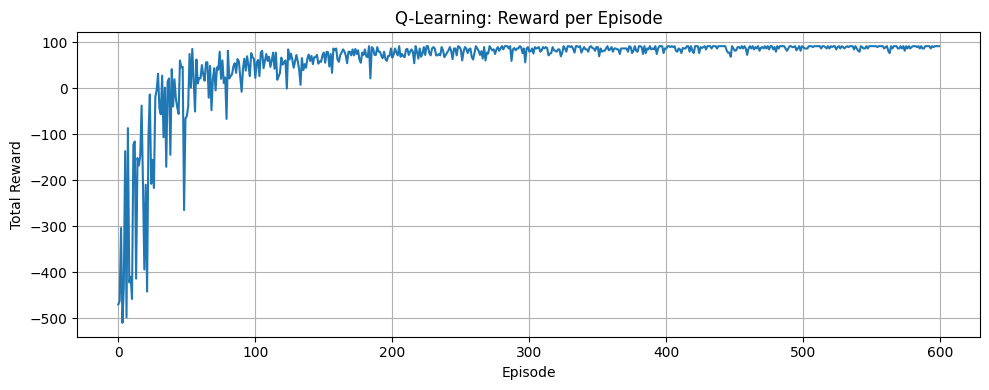

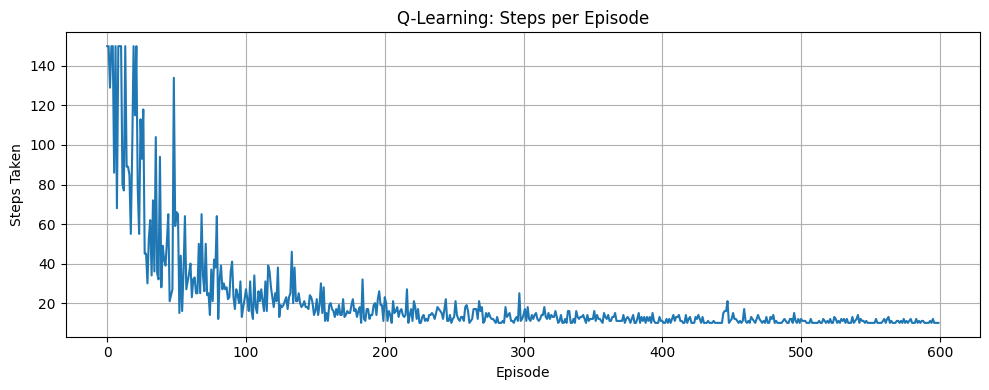


Visualization plots saved successfully.
Reinforcement Learning Experiment Completed Successfully!


In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt

# 1. Define Maze Environment
maze = np.array([
    [0, 0, 0, 1, 0, 0],
    [1, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0],
    [0, 0, 0, 1, 0, 0],
    [1, 1, 0, 0, 0, 0]
])

rows, cols = maze.shape
start = (0, 0)
goal = (5, 5)

actions = ['UP', 'DOWN', 'LEFT', 'RIGHT']
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episodes = 600
max_steps = 150

Q = np.zeros((rows * cols, len(actions)))

def state_index(state):
    return state[0] * cols + state[1]

def move(state, action):
    r, c = state
    dr, dc = moves[action]
    nr, nc = r + dr, c + dc

    if (nr < 0 or nr >= rows or
        nc < 0 or nc >= cols or maze[nr, nc] == 1):
        return state

    return (nr, nc)

def display_maze(path=None):
    path = path or []
    for r in range(rows):
        line = "|"
        for c in range(cols):
            p = (r, c)
            if p == start:
                symbol = "S"
            elif p == goal:
                symbol = "G"
            elif maze[r, c] == 1:
                symbol = "###"
            elif p in path:
                symbol = " * "
            else:
                symbol = " . "
            line += f"{symbol}|"
        print(line)
        print("+" + "---+" * cols)

print("1. Defining the Maze Environment:")
print(f"Grid Dimensions : {rows} rows x {cols} columns")
print("Start Position  :", start)
print("Goal Position   :", goal)
print("Action Space    :", actions)

print("\nInitial Maze Layout:")
display_maze()

# 2. Train Q-Learning Agent
print("\n2. Q-Learning Hyperparameters:")
print("Learning Rate (alpha)      :", alpha)
print("Discount Factor (gamma)    :", gamma)
print("Initial Exploration        :", 1.0)
print("Epsilon Decay Rate         :", epsilon_decay)
print("Minimum Epsilon            :", epsilon_min)
print("Training Episodes         :", episodes)

print("\nTraining Q-Learning Agent (600 Episodes)")
print("-" * 75)
print(f"{'Episode':<10}{'Total Reward':<16}"
      f"{'Steps Taken':<15}{'Epsilon':<12}{'Status'}")

rewards_history = []
steps_history = []
epsilon = 1.0

for episode in range(1, episodes + 1):
    state = start
    total_reward = 0
    status = "Max Steps"

    for step in range(1, max_steps + 1):
        s = state_index(state)

        if random.random() < epsilon:
            action = random.randrange(4)
        else:
            action = int(np.argmax(Q[s]))

        next_state = move(state, action)

        if next_state == goal:
            reward = 100
        elif next_state == state:
            reward = -5
        else:
            reward = -1

        ns = state_index(next_state)

        # Q-learning update
        Q[s, action] += alpha * (
            reward + gamma * np.max(Q[ns]) - Q[s, action]
        )

        state = next_state
        total_reward += reward

        if state == goal:
            status = "Goal Reached"
            break

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards_history.append(total_reward)
    steps_history.append(step)

    if episode == 1 or episode % 100 == 0:
        print(f"{episode:<10}{total_reward:<16.2f}"
              f"{step:<15}{epsilon:<12.4f}{status}")

print("-" * 75)
print(f"Training completed successfully over {episodes} episodes.")

# 3. Evaluate trained agent
print("\n3. Evaluating Trained Agent (Greedy Policy: Epsilon = 0)")
print("-" * 65)

state = start
path = [state]
total_reward = 0
success = False

for step in range(1, 37):
    s = state_index(state)

    # Select best action that does not revisit the path
    ranked_actions = np.argsort(Q[s])[::-1]
    selected = None

    for action in ranked_actions:
        candidate = move(state, int(action))
        if candidate != state and candidate not in path:
            selected = int(action)
            break

    if selected is None:
        print("No further valid move found.")
        break

    next_state = move(state, selected)
    reward = 100 if next_state == goal else -1

    print(f"Step {step:02}: From {state} --[{actions[selected]}]--> "
          f"{next_state} (Reward: {reward:.1f})")

    state = next_state
    path.append(state)
    total_reward += reward

    if state == goal:
        success = True
        break

if success:
    print("\nSuccess! Agent reached the Goal cell 'G'.")
else:
    print("\nGoal not reached. Try increasing training episodes.")

print("Total Steps in Path :", len(path) - 1)
print("Total Cumulative Reward:", total_reward)

print("\nSolved Maze with Learned Path:")
display_maze(path)

print("\nOptimal Path Sequence:")
print(" -> ".join(map(str, path)))

print("\nActions Sequence:")
print(" -> ".join(actions[
    next(i for i, d in enumerate(moves)
         if move(path[j], i) == path[j + 1])
] for j in range(len(path) - 1)))

# 4. Performance Plots
plt.figure(figsize=(10, 4))
plt.plot(rewards_history)
plt.title("Q-Learning: Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.tight_layout()
plt.savefig("maze_qlearning_rewards.png")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(steps_history)
plt.title("Q-Learning: Steps per Episode")
plt.xlabel("Episode")
plt.ylabel("Steps Taken")
plt.grid(True)
plt.tight_layout()
plt.savefig("maze_qlearning_steps.png")
plt.show()

print("\nVisualization plots saved successfully.")
print("Reinforcement Learning Experiment Completed Successfully!")
